In [5]:
from __future__ import annotations
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [26]:
@dataclass(frozen=True)
class RmmLeadCurveConfig:
    data_dir: str
    period: str = "2012-2013"
    exp_list: tuple[str, ...] = (
        "CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE"
    )
    obs_file: str | None = None          # if None, auto: rmm_obs_projected_{period}.nc
    amp_thresh: float | None = 1.0       # apply to OBS amplitude; set None to disable
    window_days: int = 60                # running window length
    min_samples: int = 30                # min paired days per window/bin
    max_lead_days: int | None = None     # optional truncate lead range (days since first valid)


@dataclass(frozen=True)
class LeadBinSpec:
    name: str
    start: int  # inclusive
    end: int    # inclusive


DEFAULT_LEAD_BINS = (
    LeadBinSpec("Wk1-2 (1-14)", 1, 14),
    LeadBinSpec("Wk3-4 (15-28)", 15, 28),
    LeadBinSpec("Wk5-6 (29-42)", 29, 42),
    LeadBinSpec("Wk7-8 (43-56)", 43, 56),
)


class RmmDiagnostics:
    """
    Finalized MJO RMM diagnostics:
      - Running (forward-window) bivariate ACC/RMSE curves vs lead day
      - Lead-bin bivariate ACC/RMSE tables and bar plots (wk1–8)
    """

    def __init__(self, cfg: RmmLeadCurveConfig, *, verbose: bool = True):
        self.cfg = cfg
        self.verbose = verbose
        self._obs = self._open_obs()

    def _log(self, msg: str):
        if self.verbose:
            print(f"[RMM-DIAG] {msg}")

    # -----------------------------
    # I/O
    # -----------------------------
    def _open_obs(self) -> xr.Dataset:
        cfg = self.cfg
        data_dir = Path(cfg.data_dir)
        obs_path = Path(cfg.obs_file) if cfg.obs_file else (data_dir / f"rmm_obs_projected_{cfg.period}.nc")
        ds = xr.open_dataset(obs_path)

        # Normalize time coord
        if "time" not in ds.coords:
            raise KeyError(f"OBS file missing coord 'time': {obs_path}")

        # Required vars
        for v in ("RMM1_obs", "RMM2_obs", "RMM_amp_obs"):
            if v not in ds:
                raise KeyError(f"OBS file missing variable '{v}': {obs_path}")

        # Ensure monotonically increasing time
        ds = ds.sortby("time")
        self._log(f"Loaded OBS: {obs_path.name}  n={ds.sizes.get('time', '??')}")
        return ds

    def _open_fcst(self, exp: str) -> xr.Dataset:
        cfg = self.cfg
        p = Path(cfg.data_dir) / f"rmm_fcst_projected_{exp}_{cfg.period}.nc"
        ds = xr.open_dataset(p)

        # Some files may carry init dimension; we allow init=1 and squeeze
        if "time" not in ds.coords:
            # If it's (init,time) but time is a dim not a coord, xarray still shows it in dims.
            if "init" in ds.dims and "time" in ds.dims and ds.sizes.get("init", 0) == 1:
                ds = ds.isel(init=0, drop=True)
            else:
                raise KeyError(f"{exp} file missing coord 'time': {p}")

        for v in ("RMM1_fcst", "RMM2_fcst"):
            if v not in ds:
                raise KeyError(f"{exp} file missing variable '{v}': {p}")

        # Sort time for deterministic lead computation
        ds = ds.sortby("time")
        return ds

    # -----------------------------
    # metrics
    # -----------------------------
    @staticmethod
    def _vector_acc(r1f, r2f, r1o, r2o) -> float:
        """
        Bivariate ACC for (RMM1,RMM2), correlation-style (remove mean).
        """
        r1f = np.asarray(r1f, dtype=float); r2f = np.asarray(r2f, dtype=float)
        r1o = np.asarray(r1o, dtype=float); r2o = np.asarray(r2o, dtype=float)

        r1f = r1f - np.nanmean(r1f); r2f = r2f - np.nanmean(r2f)
        r1o = r1o - np.nanmean(r1o); r2o = r2o - np.nanmean(r2o)

        num = np.nansum(r1f * r1o + r2f * r2o)
        den = np.sqrt(np.nansum(r1f * r1f + r2f * r2f) * np.nansum(r1o * r1o + r2o * r2o))
        if not np.isfinite(den) or den == 0:
            return np.nan
        return float(num / den)

    @staticmethod
    def _vector_rmse(r1f, r2f, r1o, r2o) -> float:
        """
        Bivariate RMSE for (RMM1,RMM2).
        """
        r1f = np.asarray(r1f, dtype=float); r2f = np.asarray(r2f, dtype=float)
        r1o = np.asarray(r1o, dtype=float); r2o = np.asarray(r2o, dtype=float)

        e1 = r1f - r1o
        e2 = r2f - r2o
        return float(np.sqrt(np.nanmean(e1 * e1 + e2 * e2)))

    # -----------------------------
    # shared alignment + masking
    # -----------------------------
    def _get_time_axis(self, ds: xr.Dataset, kind: str) -> np.ndarray:
        """
        Return a 1D array of 'valid time' values for alignment.
        Preference order:
          - ds['valid_time'] if present
          - ds['time']
        """
        if "valid_time" in ds:
            t = ds["valid_time"]
            # if valid_time carried init dim (should not after squeeze, but guard)
            if "init" in t.dims and ds.sizes.get("init", 0) == 1:
                t = t.isel(init=0, drop=True)
            return np.asarray(t.values)
        if "time" in ds.coords:
            return np.asarray(ds["time"].values)
        raise KeyError(f"{kind} dataset missing both 'valid_time' and 'time'.")

    def _get_1d_fcst_obs_aligned(self, exp: str):
        """
        Return 1D numpy arrays after:
          - squeezing init if present (init size=1)
          - aligning by common valid time (valid_time preferred)
          - selecting those times via the DATASET 'time' coordinate (assumed to be valid time)
          - applying OBS amplitude threshold (if set)
        """
        cfg = self.cfg
        fc = self._open_fcst(exp)
        obs = self._obs

        # forecast 1D
        r1f = fc["RMM1_fcst"]
        r2f = fc["RMM2_fcst"]
        tf = self._get_time_axis(fc, f"{exp} fcst")

        # obs 1D
        r1o = obs["RMM1_obs"]
        r2o = obs["RMM2_obs"]
        ao = obs["RMM_amp_obs"]
        to = self._get_time_axis(obs, "OBS")

        # Align by common valid times
        t_common = np.intersect1d(tf, to)
        if t_common.size < cfg.min_samples:
            raise ValueError(f"{exp}: too few common days after alignment: {t_common.size}")

        # IMPORTANT: select on the dataset 'time' coordinate
        # Assumption: projector saved the valid times on 'time' coord, even if valid_time exists.
        r1f = r1f.sel(time=t_common)
        r2f = r2f.sel(time=t_common)

        r1o = r1o.sel(time=t_common)
        r2o = r2o.sel(time=t_common)
        ao = ao.sel(time=t_common)

        # Amp threshold on OBS amp
        if cfg.amp_thresh is not None:
            keep = (ao >= float(cfg.amp_thresh))
            r1f = r1f.where(keep, drop=True)
            r2f = r2f.where(keep, drop=True)
            r1o = r1o.where(keep, drop=True)
            r2o = r2o.where(keep, drop=True)

        n = int(r1f.sizes["time"])
        if n < cfg.min_samples:
            raise ValueError(f"{exp}: too few samples after amp_thresh: n={n}")

        # Lead day since first retained day (integer days)
        tvals = r1f["time"].values.astype("datetime64[D]")
        lead = (tvals - tvals[0]).astype("timedelta64[D]").astype(int)

        # to 1D numpy
        r1f_np = np.asarray(r1f.values, dtype=float).reshape(-1)
        r2f_np = np.asarray(r2f.values, dtype=float).reshape(-1)
        r1o_np = np.asarray(r1o.values, dtype=float).reshape(-1)
        r2o_np = np.asarray(r2o.values, dtype=float).reshape(-1)

        return r1f_np, r2f_np, r1o_np, r2o_np, lead

    # -----------------------------
    # running curves
    # -----------------------------
    def compute_running_curves(self, exp: str) -> xr.Dataset:
        """
        Running (forward-window) ACC/RMSE curves versus lead day.

        Choices:
          - Align forecast and obs by common valid time
          - Apply amplitude threshold using OBS amplitude (amp_thresh)
          - Define lead_day relative to first retained valid time
          - Forward running window: [L, L+window_days)
        """
        cfg = self.cfg
        r1f, r2f, r1o, r2o, lead = self._get_1d_fcst_obs_aligned(exp)

        max_lead = int(cfg.max_lead_days) if (cfg.max_lead_days is not None) else int(np.nanmax(lead))
        win = int(cfg.window_days)

        acc_vals = np.full(max_lead + 1, np.nan, dtype=float)
        rmse_vals = np.full(max_lead + 1, np.nan, dtype=float)
        n_vals = np.zeros(max_lead + 1, dtype=int)

        for L in range(0, max_lead + 1):
            m = np.where((lead >= L) & (lead < L + win))[0]
            n_vals[L] = int(m.size)
            if m.size < cfg.min_samples:
                continue
            acc_vals[L] = self._vector_acc(r1f[m], r2f[m], r1o[m], r2o[m])
            rmse_vals[L] = self._vector_rmse(r1f[m], r2f[m], r1o[m], r2o[m])

        return xr.Dataset(
            data_vars={
                "ACC_VEC": (("lead_day",), acc_vals),
                "RMSE_VEC": (("lead_day",), rmse_vals),
                "n_samples": (("lead_day",), n_vals),
            },
            coords={"lead_day": np.arange(max_lead + 1, dtype=int)},
            attrs={
                "exp": exp,
                "period": cfg.period,
                "amp_thresh": float(cfg.amp_thresh) if (cfg.amp_thresh is not None) else np.nan,
                "window_days": int(cfg.window_days),
                "min_samples": int(cfg.min_samples),
                "window_type": "forward",
            },
        )

    def plot_lead_acc_rmse_all(
        self,
        *,
        title: str | None = None,
        show: bool = True,
        out_png: str | None = None,
        acc_refline: float | None = 0.5,
    ):
        cfg = self.cfg
        fig, axes = plt.subplots(2, 1, figsize=(10.8, 6.4), sharex=True)

        for exp in cfg.exp_list:
            ds = self.compute_running_curves(exp)
            x = ds["lead_day"].values
            axes[0].plot(x, ds["ACC_VEC"].values, label=exp)
            axes[1].plot(x, ds["RMSE_VEC"].values, label=exp)

        if acc_refline is not None:
            axes[0].axhline(float(acc_refline), linewidth=1.0)

        axes[0].set_ylabel("Bivariate ACC (running, forward window)")
        axes[0].set_ylim(-1.0, 1.0)

        axes[1].set_ylabel("Bivariate RMSE (running, forward window)")
        axes[1].set_xlabel("Lead day (days since first retained valid time)")

        if title is None:
            amp_txt = f"amp≥{cfg.amp_thresh}" if cfg.amp_thresh is not None else "no amp filter"
            title = f"MJO RMM running skill ({cfg.period})  {amp_txt}  win={cfg.window_days}d"
        axes[0].set_title(title)

        axes[0].legend(ncol=2, frameon=False, loc="upper right")
        plt.tight_layout()

        if out_png:
            out_png = str(out_png)
            Path(out_png).parent.mkdir(parents=True, exist_ok=True)
            plt.savefig(out_png, dpi=200)

        if show:
            plt.show()
        else:
            plt.close(fig)

    # -----------------------------
    # lead-bin metrics
    # -----------------------------
    def compute_lead_bin_metrics(
        self,
        exp: str,
        *,
        bins: tuple[LeadBinSpec, ...] = DEFAULT_LEAD_BINS,
        require_min_samples: int | None = None,
    ) -> xr.Dataset:
        cfg = self.cfg
        min_samp = int(require_min_samples) if (require_min_samples is not None) else int(cfg.min_samples)

        r1f, r2f, r1o, r2o, lead = self._get_1d_fcst_obs_aligned(exp)

        names = [b.name for b in bins]
        acc = np.full(len(bins), np.nan, dtype=float)
        rmse = np.full(len(bins), np.nan, dtype=float)
        ns = np.zeros(len(bins), dtype=int)

        for i, b in enumerate(bins):
            m = np.where((lead >= int(b.start)) & (lead <= int(b.end)))[0]
            ns[i] = int(m.size)
            if m.size < min_samp:
                continue
            acc[i] = self._vector_acc(r1f[m], r2f[m], r1o[m], r2o[m])
            rmse[i] = self._vector_rmse(r1f[m], r2f[m], r1o[m], r2o[m])

        return xr.Dataset(
            data_vars={
                "ACC_VEC": (("lead_bin",), acc),
                "RMSE_VEC": (("lead_bin",), rmse),
                "n_samples": (("lead_bin",), ns),
                "lead_start": (("lead_bin",), np.array([b.start for b in bins], dtype=int)),
                "lead_end": (("lead_bin",), np.array([b.end for b in bins], dtype=int)),
            },
            coords={"lead_bin": np.asarray(names, dtype="U")},
            attrs={
                "exp": exp,
                "period": cfg.period,
                "amp_thresh": float(cfg.amp_thresh) if (cfg.amp_thresh is not None) else np.nan,
                "min_samples": min_samp,
            },
        )

    def compute_lead_bin_table(
        self,
        *,
        bins: tuple[LeadBinSpec, ...] = DEFAULT_LEAD_BINS,
        require_min_samples: int | None = None,
    ) -> xr.Dataset:
        cfg = self.cfg
        all_ds = []
        for exp in cfg.exp_list:
            ds = self.compute_lead_bin_metrics(exp, bins=bins, require_min_samples=require_min_samples)
            all_ds.append(ds.expand_dims(exp=[exp]))
        return xr.concat(all_ds, dim="exp")

    def plot_lead_bin_bars(
        self,
        *,
        bins: tuple[LeadBinSpec, ...] = DEFAULT_LEAD_BINS,
        require_min_samples: int | None = None,
        show: bool = True,
        out_png: str | None = None,
        title: str | None = None,
        acc_refline: float | None = 0.5,
        annotate_n: bool = True,
    ) -> xr.Dataset:
        cfg = self.cfg
        tab = self.compute_lead_bin_table(bins=bins, require_min_samples=require_min_samples)

        lead_bins = tab["lead_bin"].values.tolist()
        exps = tab["exp"].values.tolist()

        ACC = np.asarray(tab["ACC_VEC"].values, dtype=float)    # [exp, bin]
        RMSE = np.asarray(tab["RMSE_VEC"].values, dtype=float)  # [exp, bin]
        NS = np.asarray(tab["n_samples"].values, dtype=int)

        n_exp = len(exps)
        n_bin = len(lead_bins)

        x = np.arange(n_bin)
        width = 0.8 / max(n_exp, 1)

        fig, axes = plt.subplots(2, 1, figsize=(12.8, 7.2), sharex=True)

        for j, exp in enumerate(exps):
            xpos = x - 0.4 + width / 2 + j * width

            axes[0].bar(xpos, ACC[j, :], width=width, label=exp)
            axes[1].bar(xpos, RMSE[j, :], width=width, label=exp)

            if annotate_n:
                for k in range(n_bin):
                    if np.isfinite(ACC[j, k]):
                        axes[0].text(xpos[k], ACC[j, k], f"{NS[j, k]}", ha="center", va="bottom", fontsize=8)
                    if np.isfinite(RMSE[j, k]):
                        axes[1].text(xpos[k], RMSE[j, k], f"{NS[j, k]}", ha="center", va="bottom", fontsize=8)

        if acc_refline is not None:
            axes[0].axhline(float(acc_refline), linewidth=1.0)

        axes[0].set_ylabel("Bivariate ACC (RMM vector)")
        axes[0].set_ylim(-1.0, 1.0)

        axes[1].set_ylabel("Bivariate RMSE (RMM vector)")
        axes[1].set_xlabel("Lead bin (days since first retained valid time)")

        axes[1].set_xticks(x)
        axes[1].set_xticklabels(lead_bins)

        if title is None:
            amp_txt = f"amp≥{cfg.amp_thresh}" if cfg.amp_thresh is not None else "no amp filter"
            title = f"MJO RMM lead-bin skill ({cfg.period})  {amp_txt}"
        axes[0].set_title(title)

        axes[0].legend(ncol=2, frameon=False, loc="upper right")
        plt.tight_layout()

        if out_png:
            out_png = str(out_png)
            Path(out_png).parent.mkdir(parents=True, exist_ok=True)
            plt.savefig(out_png, dpi=200)

        if show:
            plt.show()
        else:
            plt.close(fig)

        return tab

[RMM-DIAG] Loaded OBS: rmm_obs_projected_2012-2013.nc  n=730


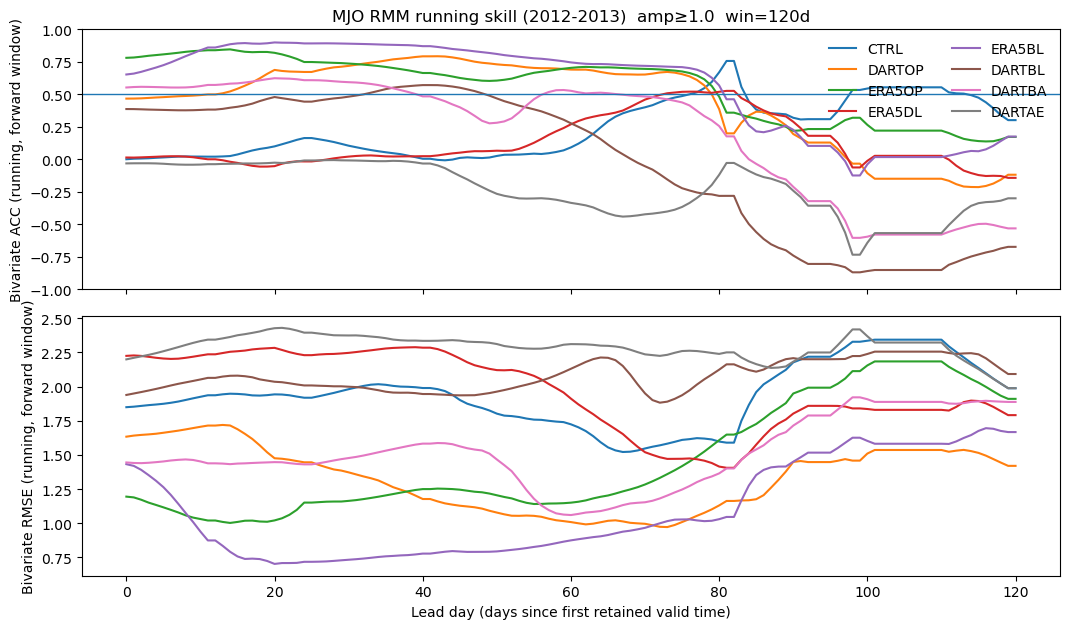

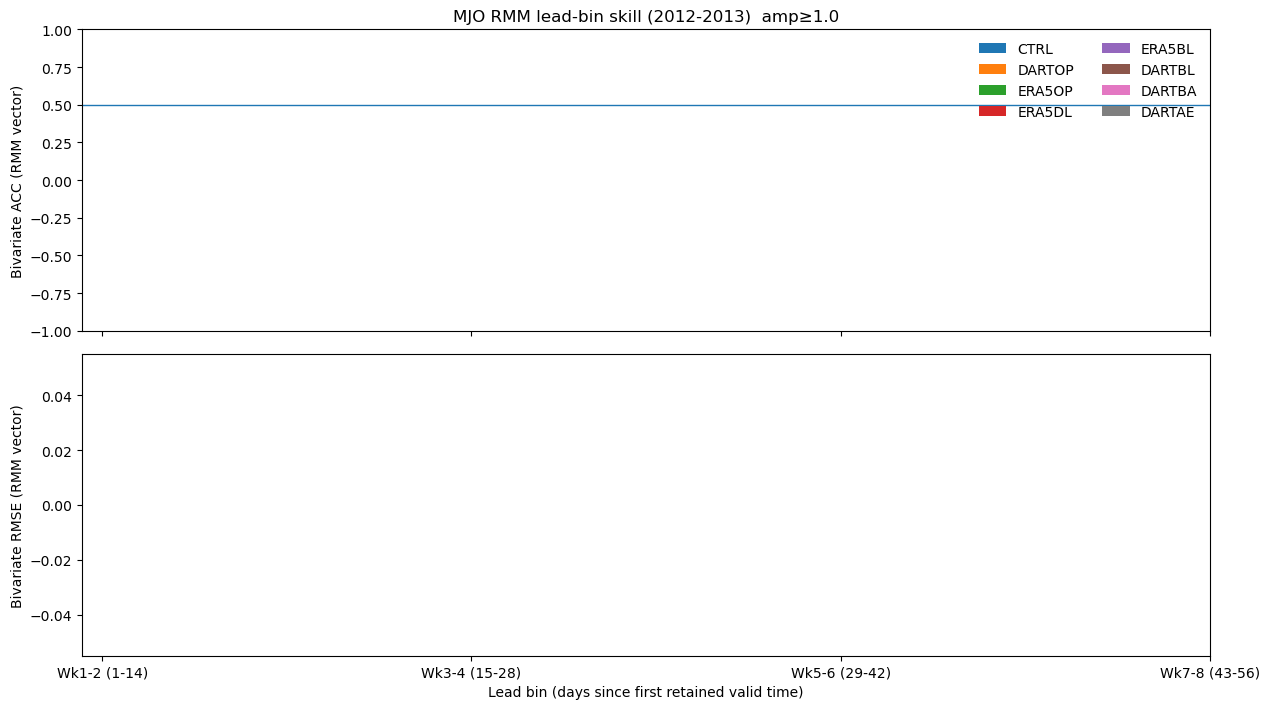

<xarray.Dataset> Size: 2kB
Dimensions:     (exp: 8, lead_bin: 4)
Coordinates:
  * exp         (exp) object 64B 'CTRL' 'DARTOP' 'ERA5OP' ... 'DARTBA' 'DARTAE'
  * lead_bin    (lead_bin) <U13 208B 'Wk1-2 (1-14)' ... 'Wk7-8 (43-56)'
Data variables:
    ACC_VEC     (exp, lead_bin) float64 256B nan nan nan nan ... nan nan nan nan
    RMSE_VEC    (exp, lead_bin) float64 256B nan nan nan nan ... nan nan nan nan
    n_samples   (exp, lead_bin) int64 256B 13 9 13 14 13 9 ... 13 14 13 9 13 14
    lead_start  (exp, lead_bin) int64 256B 1 15 29 43 1 15 ... 29 43 1 15 29 43
    lead_end    (exp, lead_bin) int64 256B 14 28 42 56 14 28 ... 56 14 28 42 56
Attributes:
    exp:          CTRL
    period:       2012-2013
    amp_thresh:   1.0
    min_samples:  15


In [29]:
if __name__ == "__main__":
    work_dir = Path("/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper")
    data_dir = work_dir / "figure_data" / "mjo"
    fig_dir = work_dir / "mjo_analysis"

    period = "2012-2013"
    exp_list = ("CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE")
    amp_thresh = 1.0
    window_days = 120
    min_samples = 15
    max_lead_days = 120

    cfg = RmmLeadCurveConfig(
        data_dir=str(data_dir),
        period=period,
        exp_list=exp_list,
        amp_thresh=amp_thresh,
        window_days=window_days,
        min_samples=min_samples,
        max_lead_days=max_lead_days,
    )

    diag = RmmDiagnostics(cfg, verbose=True)

    # 1) Running curves figure
    out_png1 = fig_dir / "rmm_figs" / "rmm_lead_ACC_RMSE_all.png"
    out_png1.parent.mkdir(parents=True, exist_ok=True)
    diag.plot_lead_acc_rmse_all(out_png=str(out_png1), show=True)

    # 2) Lead-bin bars + save table
    out_png2 = fig_dir / f"rmm_leadbin_ACC_RMSE_bar_{period}.png"
    out_png2.parent.mkdir(parents=True, exist_ok=True)
    tab = diag.plot_lead_bin_bars(
        out_png=str(out_png2),
        show=True,
        annotate_n=True,
        acc_refline=0.5,
    )
    print(tab)
    
    out_nc = fig_dir / f"rmm_leadbin_skill_{period}.nc"
    out_nc.parent.mkdir(parents=True, exist_ok=True)
    tab.to_netcdf(str(out_nc))
